# 02 - Temel model (E0)

Veri yükleyici, DeepLabV3+ modeli ve eğitim döngüsü burada kuruldu; RGB girdiyle 3 sınıflı temel model eğitilip makaledeki sonuçla karşılaştırıldı. Fonksiyonların son hali `common.py` dosyasında.

## 1. Kurulum

In [2]:
!pip install -q segmentation-models-pytorch==0.5.0

from google.colab import drive
drive.mount('/content/drive')

import os, glob, random, zipfile, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import segmentation_models_pytorch as smp

# Proje yolları
ROOT     = '/content/drive/MyDrive/multispectral-weed-segmentation'
DATA_DIR = f'{ROOT}/data'
CKPT_DIR = f'{ROOT}/checkpoints'
RES_DIR  = f'{ROOT}/results'

# Veriyi /content'e aç (zip Drive'da hazır, tekrar indirmiyoruz)
ZIP_PATH = f'{DATA_DIR}/weedsgalore-dataset.zip'
LOCAL = '/content/data'
if not os.path.exists(LOCAL):
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(LOCAL)
DATASET = os.path.dirname(glob.glob(f'{LOCAL}/**/2023-05-25', recursive=True)[0])

# Sabitler (01_kesif ile aynı)
DATES    = ['2023-05-25', '2023-05-30', '2023-06-06', '2023-06-15']
BANDS    = ['B', 'G', 'R', 'RE', 'NIR']
SINIFLAR = ['arka plan', 'mısır', 'amaranth', 'darıcan', 'quickweed', 'diğer ot']

# Resmi split listeleri
splits = {}
for s in ['train', 'val', 'test']:
    with open(f'{DATASET}/splits/{s}.txt') as f:
        splits[s] = [satir.strip() for satir in f if satir.strip()]

# EDA'da yalnız train'den hesaplanan normalizasyon istatistikleri (B, G, R, RE, NIR sırasıyla)
NORM_ORT = np.load(f'{RES_DIR}/norm_ort.npy')
NORM_STD = np.load(f'{RES_DIR}/norm_std.npy')

# Tekrarlanabilirlik: Python, NumPy ve PyTorch tohumlarını sabitle
SEED = 42
def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed(SEED)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Cihaz:', DEVICE, '|', torch.cuda.get_device_name(0) if DEVICE == 'cuda' else 'GPU YOK!')
print('torch', torch.__version__, '| smp', smp.__version__)
print('Veri kökü:', DATASET)
print('Split boyutları:', {s: len(v) for s, v in splits.items()})
print('Normalizasyon ort:', NORM_ORT.round(3), '| std:', NORM_STD.round(3))

## 2. Dataset ve veri artırma

Belleğe alındı: 156 görüntü, 562 MB
İndeks ort: {'NDVI': -0.059, 'ExG': 0.014} | std: {'NDVI': 0.147, 'ExG': 0.108}
rgb       train x(3, 512, 512) y(512, 512) | val x(3, 608, 608) | y değerleri [0, 1, 2, 255]
rgb_exg   train x(4, 512, 512) y(512, 512) | val x(4, 608, 608) | y değerleri [0, 1, 2, 255]
msi       train x(5, 512, 512) y(512, 512) | val x(5, 608, 608) | y değerleri [0, 1, 2, 255]
msi_ndvi  train x(6, 512, 512) y(512, 512) | val x(6, 608, 608) | y değerleri [0, 1, 2, 255]
6 sınıf y değerleri: [0, 1, 2, 3, 4, 5, 255]


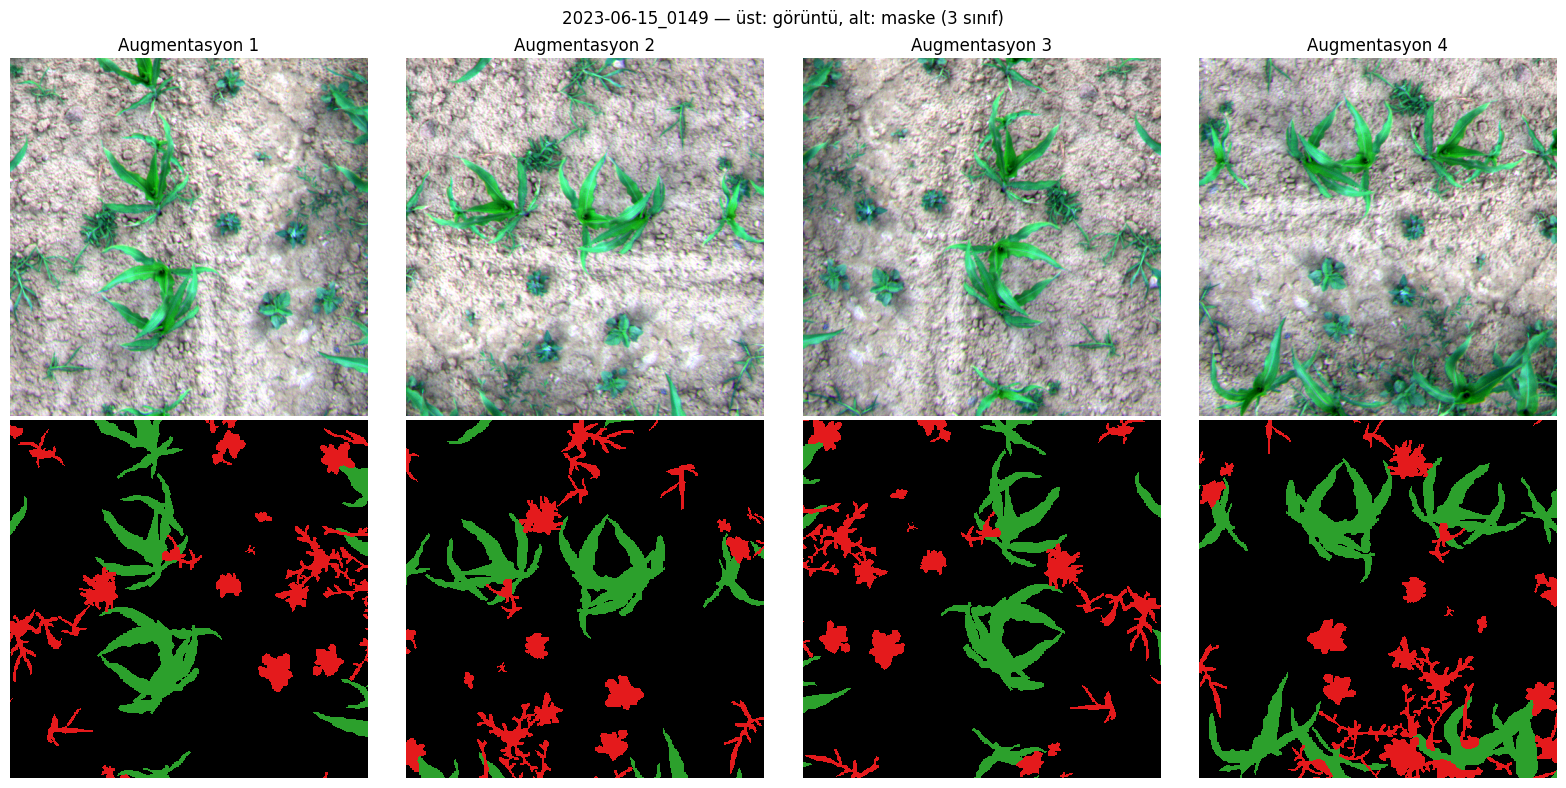

In [2]:
IGNORE = 255                                  # kayıpta ve metrikte sayılmayacak piksel (dolgu alanı)
BANT_IDX = {b: i for i, b in enumerate(BANDS)}

# E1'deki dört giriş koşulu. İlk üç kanal hep R, G, B: ImageNet ağırlıkları bu sırayı bekliyor
KANAL_SECIMI = {'rgb':      ['R', 'G', 'B'],
                'rgb_exg':  ['R', 'G', 'B', 'ExG'],
                'msi':      ['R', 'G', 'B', 'RE', 'NIR'],
                'msi_ndvi': ['R', 'G', 'B', 'RE', 'NIR', 'NDVI']}

# 156 görüntünün hepsini bir kez belleğe al (uint16 olarak ~560 MB). Her epoch diskten okumaktan çok hızlı
def ham_oku(ad):
    return np.stack([np.array(Image.open(f'{DATASET}/{ad[:10]}/images/{ad}_{b}.png')) for b in BANDS])
def maske_oku(ad):
    return np.array(Image.open(f'{DATASET}/{ad[:10]}/semantics/{ad}.png'))

tum_adlar = splits['train'] + splits['val'] + splits['test']
HAM   = {ad: ham_oku(ad) for ad in tum_adlar}
MASKE = {ad: maske_oku(ad) for ad in tum_adlar}
print(f'Belleğe alındı: {len(HAM)} görüntü, {sum(v.nbytes for v in HAM.values()) / 1e6:.0f} MB')

# İndeksler: 0–1 aralığındaki bantlardan hesaplanır
def indeksler(x):
    B, G, R, RE, NIR = x
    return {'NDVI': (NIR - R) / (NIR + R + 1e-6),          # NIR gerekir -> yalnız multispektral
            'ExG':  (2 * G - R - B) / (B + G + R + 1e-6)}  # yalnız RGB'den hesaplanır

# İndeksleri de bantlar gibi standartlaştırmak için yalnız train'den ortalama/std
_ort, _kare = {'NDVI': [], 'ExG': []}, {'NDVI': [], 'ExG': []}
for ad in splits['train']:
    ind = indeksler(HAM[ad].astype(np.float32) / 65535)
    for k in ind:
        _ort[k].append(ind[k].mean()); _kare[k].append((ind[k] ** 2).mean())
IND_ORT = {k: float(np.mean(_ort[k])) for k in _ort}
IND_STD = {k: float(np.sqrt(np.mean(_kare[k]) - IND_ORT[k] ** 2)) for k in _ort}
print('İndeks ort:', {k: round(v, 3) for k, v in IND_ORT.items()}, '| std:', {k: round(v, 3) for k, v in IND_STD.items()})

# Dataset sınıfı
class OtDataset(Dataset):
    def __init__(self, adlar, kanallar='rgb', n_sinif=3, egitim=False, kirp=512):
        self.adlar    = adlar
        self.kanallar = KANAL_SECIMI[kanallar]
        self.n_sinif  = n_sinif
        self.egitim   = egitim
        self.kirp     = kirp

    def __len__(self):
        return len(self.adlar)

    def __getitem__(self, i):
        ad = self.adlar[i]
        x = HAM[ad].astype(np.float32) / 65535
        y = MASKE[ad].astype(np.int64)
        if self.n_sinif == 3:
            y = np.where(y > 1, 2, y)                    # tüm ot türleri -> 2 ("ot")

        if self.egitim:
            # Rastgele 512×512 kırpma - çözünürlük korunur (resize yok)
            k = self.kirp
            r, c = np.random.randint(0, 600 - k + 1, size=2)
            x, y = x[:, r:r + k, c:c + k], y[r:r + k, c:c + k]
            # Çevirme + 90° döndürme (8 olası yön) - nadir görüntüde gerçekçi
            if np.random.rand() < 0.5: x, y = x[:, :, ::-1], y[:, ::-1]
            if np.random.rand() < 0.5: x, y = x[:, ::-1, :], y[::-1, :]
            n = np.random.randint(4)
            x, y = np.rot90(x, n, axes=(1, 2)), np.rot90(y, n)
            # Parlaklık: tüm bantlara aynı çarpan -> bant oranları (NDVI, ExG) değişmez
            x = x * np.random.uniform(0.9, 1.1)
            # Çok hafif sensör gürültüsü
            x = np.clip(x + np.random.normal(0, 0.01, x.shape).astype(np.float32), 0, 1)

        # Kanalları seç ve standartlaştır: (değer − train ortalaması) / train std
        ind = indeksler(x) if any(k in IND_ORT for k in self.kanallar) else {}
        kanal = []
        for k in self.kanallar:
            if k in BANT_IDX:
                j = BANT_IDX[k]
                kanal.append((x[j] - NORM_ORT[j]) / NORM_STD[j])
            else:
                kanal.append((ind[k] - IND_ORT[k]) / IND_STD[k])
        x = np.stack(kanal).astype(np.float32)

        # Değerlendirmede 600 -> 608 dolgu (model girişi 32'ye bölünebilmeli); dolgu pikselleri IGNORE
        if not self.egitim:
            x = np.pad(x, ((0, 0), (0, 8), (0, 8)), mode='reflect')
            y = np.pad(y, ((0, 8), (0, 8)), constant_values=IGNORE)

        return torch.from_numpy(np.ascontiguousarray(x)), torch.from_numpy(np.ascontiguousarray(y))

# DataLoader'ın paralel işçileri aynı rastgele sayıları üretmesin diye her birine ayrı NumPy tohumu
def worker_init(worker_id):
    np.random.seed((torch.initial_seed() + worker_id) % 2 ** 32)

# Hızlı kontrol: boyutlar, kanal sayıları, sınıf değerleri
for mod in KANAL_SECIMI:
    xt, yt = OtDataset(splits['train'], mod, 3, egitim=True)[0]
    xv, yv = OtDataset(splits['val'],   mod, 3, egitim=False)[0]
    print(f'{mod:9s} train x{tuple(xt.shape)} y{tuple(yt.shape)} | val x{tuple(xv.shape)} '
          f'| y değerleri {torch.unique(yv).tolist()}')
print('6 sınıf y değerleri:', torch.unique(OtDataset(splits['val'], 'rgb', 6)[0][1]).tolist())

# Görsel kontrol: aynı görüntünün 4 farklı augmentasyonu - maske görüntüyle birlikte dönüyor mu?
from matplotlib.colors import ListedColormap
CMAP3 = ListedColormap(['#000000', '#2ca02c', '#e41a1c'])
ds_goster = OtDataset([splits['train'][-1]], 'rgb', 3, egitim=True)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for j in range(4):
    x, y = ds_goster[0]
    rgb = x[:3].numpy() * NORM_STD[[2, 1, 0], None, None] + NORM_ORT[[2, 1, 0], None, None]
    rgb = np.clip((rgb.transpose(1, 2, 0) - 0.15) / 0.6, 0, 1)
    axes[0, j].imshow(rgb); axes[0, j].set_title(f'Augmentasyon {j + 1}'); axes[0, j].axis('off')
    axes[1, j].imshow(y, cmap=CMAP3, vmin=-0.5, vmax=2.5, interpolation='nearest'); axes[1, j].axis('off')
plt.suptitle(f'{splits["train"][-1]} — üst: görüntü, alt: maske (3 sınıf)')
plt.tight_layout(); plt.show()

## 3. Model, metrikler ve kısa deneme

In [3]:
# Model: DeepLabV3+ - ResNet-50 omurga, ImageNet ağırlıklı
def model_olustur(n_kanal, n_sinif):
    return smp.DeepLabV3Plus(encoder_name='resnet50', encoder_weights='imagenet',
                             in_channels=n_kanal, classes=n_sinif).to(DEVICE)

# Karışıklık matrisi: satır = gerçek sınıf, sütun = tahmin. IGNORE pikselleri sayılmaz
def karisiklik(pred, y, n):
    gecerli = y != IGNORE
    return torch.bincount(y[gecerli] * n + pred[gecerli], minlength=n * n).reshape(n, n)

# Matristen tüm metrikler
def metrikler(cm):
    cm = cm.double()
    tp, gercek, tahmin = cm.diag(), cm.sum(1), cm.sum(0)
    iou       = tp / (gercek + tahmin - tp).clamp(min=1)
    recall    = tp / gercek.clamp(min=1)
    precision = tp / tahmin.clamp(min=1)
    f1        = 2 * precision * recall / (precision + recall).clamp(min=1e-9)
    # Saha metrikleri - tüm ot türleri (sınıf ≥ 2) tek "ot" sayılır
    ot_recall = cm[2:, 2:].sum() / cm[2:, :].sum()          # gerçek ot pikselinin "ot" bulunan oranı
    misir_fp  = cm[1, 2:].sum() / cm[1, :].sum()            # mısır pikselinin "ot" sanılan oranı
    return {'miou': iou.mean().item(), 'iou': iou.cpu().numpy(),
            'recall': recall.cpu().numpy(), 'precision': precision.cpu().numpy(), 'f1': f1.cpu().numpy(),
            'ot_recall': ot_recall.item(), 'misir_fp': misir_fp.item()}

# Bir split'in tamamını değerlendir: toplam matris + tarih başına matris
@torch.no_grad()
def degerlendir(model, ds, n_sinif, bs=4):
    model.eval()
    yuk = DataLoader(ds, batch_size=bs, shuffle=False, num_workers=2)
    cm_top   = torch.zeros(n_sinif, n_sinif, dtype=torch.long, device=DEVICE)
    cm_tarih = {d: torch.zeros_like(cm_top) for d in DATES}
    i = 0
    for x, y in yuk:
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.autocast('cuda', dtype=torch.float16):  # karışık hassasiyet: T4'te ~2 kat hızlı
            pred = model(x).argmax(1)
        for b in range(len(x)):
            cm = karisiklik(pred[b], y[b], n_sinif)
            cm_top += cm
            cm_tarih[ds.adlar[i][:10]] += cm
            i += 1
    return cm_top, cm_tarih

# Test geçişi - RGB, 3 sınıf
model = model_olustur(3, 3)
print(f'Parametre sayısı: {sum(p.numel() for p in model.parameters()) / 1e6:.1f} M')
print('MSI için ilk konvolüsyon ağırlığı:', tuple(model_olustur(5, 3).encoder.conv1.weight.shape),
      '(çıkış, GİRİŞ KANALI, yükseklik, genişlik)')

yuk_tr = DataLoader(OtDataset(splits['train'], 'rgb', 3, egitim=True), batch_size=8,
                    shuffle=True, num_workers=2, worker_init_fn=worker_init, drop_last=True)
x, y = next(iter(yuk_tr))
x, y = x.to(DEVICE), y.to(DEVICE)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
scaler = torch.amp.GradScaler()
torch.cuda.reset_peak_memory_stats()
t0 = time.time()
for _ in range(5):                                          # 5 eğitim adımı: hız ve bellek ölçümü
    with torch.autocast('cuda', dtype=torch.float16):
        cikti = model(x)
        kayip = F.cross_entropy(cikti, y, ignore_index=IGNORE)
    opt.zero_grad(); scaler.scale(kayip).backward(); scaler.step(opt); scaler.update()
torch.cuda.synchronize()
print(f'Çıkış boyutu: {tuple(cikti.shape)} | kayıp: {kayip.item():.3f}')
print(f'Adım süresi: {(time.time() - t0) / 5:.2f} sn | en yüksek GPU belleği: {torch.cuda.max_memory_allocated() / 1e9:.1f} GB')

m = metrikler(degerlendir(model, OtDataset(splits['val'], 'rgb', 3), 3)[0])
print('Eğitilmemiş model val IoU:', dict(zip(['arka plan', 'mısır', 'ot'], m['iou'].round(3))),
      f"| mIoU {m['miou']:.3f} | ot recall {m['ot_recall']:.3f}")

Parametre sayısı: 26.7 M
MSI için ilk konvolüsyon ağırlığı: (64, 5, 7, 7) (çıkış, GİRİŞ KANALI, yükseklik, genişlik)
Çıkış boyutu: (8, 3, 512, 512) | kayıp: 0.606
Adım süresi: 1.69 sn | en yüksek GPU belleği: 3.5 GB
Eğitilmemiş model val IoU: {'arka plan': np.float64(0.528), 'mısır': np.float64(0.039), 'ot': np.float64(0.132)} | mIoU 0.233 | ot recall 0.732


## 4. Eğitim döngüsü ve E0

[E0_rgb_3s] ep   1 | train 0.662 | val 0.969 | val mIoU 0.427 | en iyi 0.427 (ep 1) | 0.2 dk
[E0_rgb_3s] ep  10 | train 0.096 | val 0.183 | val mIoU 0.570 | en iyi 0.672 (ep 7) | 1.4 dk
[E0_rgb_3s] ep  20 | train 0.081 | val 0.089 | val mIoU 0.683 | en iyi 0.727 (ep 17) | 2.9 dk
[E0_rgb_3s] ep  30 | train 0.065 | val 0.072 | val mIoU 0.750 | en iyi 0.762 (ep 27) | 4.3 dk
[E0_rgb_3s] ep  40 | train 0.063 | val 0.069 | val mIoU 0.769 | en iyi 0.769 (ep 40) | 5.5 dk
[E0_rgb_3s] ep  50 | train 0.058 | val 0.067 | val mIoU 0.769 | en iyi 0.769 (ep 50) | 6.8 dk
[E0_rgb_3s] ep  60 | train 0.058 | val 0.067 | val mIoU 0.765 | en iyi 0.784 (ep 52) | 8.1 dk
[E0_rgb_3s] ep  70 | train 0.054 | val 0.063 | val mIoU 0.787 | en iyi 0.787 (ep 70) | 9.4 dk
[E0_rgb_3s] ep  80 | train 0.053 | val 0.059 | val mIoU 0.797 | en iyi 0.798 (ep 77) | 10.8 dk
[E0_rgb_3s] ep  90 | train 0.053 | val 0.060 | val mIoU 0.796 | en iyi 0.799 (ep 87) | 12.1 dk
[E0_rgb_3s] ep 100 | train 0.051 | val 0.060 | val mIoU 0.79

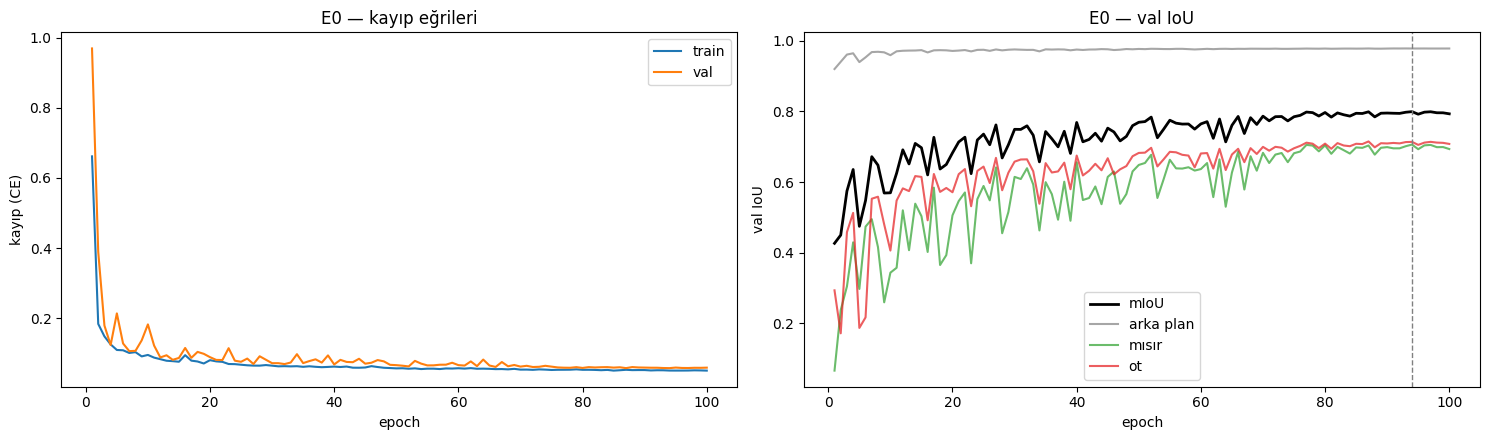

             IoU  precision  recall     F1
arka plan  0.978      0.989   0.989  0.989
mısır      0.706      0.852   0.805  0.828
ot         0.714      0.825   0.841  0.833
mIoU 0.800 | ot recall 0.841 | mısırın ot sanılma oranı 0.066
Tarih başına val mIoU: {'2023-05-25': 0.553, '2023-05-30': 0.705, '2023-06-06': 0.814, '2023-06-15': 0.759}


In [4]:
def kayip_olustur(tur='ce', agirlik=None):
    """Kayıp fonksiyonu. Şimdilik ağırlıklı/ağırlıksız çapraz entropi; E2'de focal + Dice eklenecek."""
    w = torch.tensor(agirlik, dtype=torch.float32, device=DEVICE) if agirlik is not None else None
    if tur == 'ce':
        return nn.CrossEntropyLoss(weight=w, ignore_index=IGNORE)
    raise ValueError(f'Bilinmeyen kayıp: {tur}')

@torch.no_grad()
def degerlendir(model, ds, n_sinif, kayip_fn=None, bs=4):
    """Hücre 3'teki fonksiyonun yerine geçer: artık val kaybını da hesaplıyor."""
    model.eval()
    yuk = DataLoader(ds, batch_size=bs, shuffle=False, num_workers=2)
    cm_top   = torch.zeros(n_sinif, n_sinif, dtype=torch.long, device=DEVICE)
    cm_tarih = {d: torch.zeros_like(cm_top) for d in DATES}
    kayip_top, i = 0.0, 0
    for x, y in yuk:
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.autocast('cuda', dtype=torch.float16):
            cikti = model(x)
            if kayip_fn is not None:
                kayip_top += kayip_fn(cikti, y).item() * len(x)
        pred = cikti.argmax(1)
        for b in range(len(x)):
            cm = karisiklik(pred[b], y[b], n_sinif)
            cm_top += cm
            cm_tarih[ds.adlar[i][:10]] += cm
            i += 1
    return cm_top, cm_tarih, kayip_top / len(ds)

def egit(deney, kanallar='rgb', n_sinif=3, epoch=100, bs=8, lr=1e-3, kayip='ce', agirlik=None, seed=SEED):
    set_seed(seed)
    ds_tr = OtDataset(splits['train'], kanallar, n_sinif, egitim=True)
    ds_va = OtDataset(splits['val'],   kanallar, n_sinif, egitim=False)
    yuk = DataLoader(ds_tr, batch_size=bs, shuffle=True, num_workers=2, drop_last=True,
                     worker_init_fn=worker_init, generator=torch.Generator().manual_seed(seed))

    model    = model_olustur(len(KANAL_SECIMI[kanallar]), n_sinif)
    kayip_fn = kayip_olustur(kayip, agirlik)
    opt      = torch.optim.Adam(model.parameters(), lr=lr)
    toplam   = epoch * len(yuk)
    sched    = torch.optim.lr_scheduler.LambdaLR(opt, lambda a: (1 - a / toplam) ** 0.9)  # "poly" azalma
    scaler   = torch.amp.GradScaler()

    gecmis, en_iyi, en_iyi_ep, t0 = [], -1.0, 0, time.time()
    for ep in range(1, epoch + 1):
        model.train()
        tr_kayip = 0.0
        for x, y in yuk:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            with torch.autocast('cuda', dtype=torch.float16):
                k = kayip_fn(model(x), y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(k).backward(); scaler.step(opt); scaler.update()
            sched.step()
            tr_kayip += k.item()

        cm, _, va_kayip = degerlendir(model, ds_va, n_sinif, kayip_fn)
        m = metrikler(cm)
        gecmis.append({'epoch': ep, 'train_kayip': tr_kayip / len(yuk), 'val_kayip': va_kayip,
                       'val_miou': m['miou'], 'ot_recall': m['ot_recall'], 'misir_fp': m['misir_fp'],
                       'lr': sched.get_last_lr()[0], **{f'iou_{c}': v for c, v in enumerate(m['iou'])}})
        if m['miou'] > en_iyi:
            en_iyi, en_iyi_ep = m['miou'], ep
            torch.save(model.state_dict(), f'{CKPT_DIR}/{deney}.pt')
        if ep == 1 or ep % 10 == 0:
            print(f'[{deney}] ep {ep:3d} | train {gecmis[-1]["train_kayip"]:.3f} | val {va_kayip:.3f} '
                  f'| val mIoU {m["miou"]:.3f} | en iyi {en_iyi:.3f} (ep {en_iyi_ep}) | {(time.time() - t0) / 60:.1f} dk')

    df = pd.DataFrame(gecmis)
    df.to_csv(f'{RES_DIR}/{deney}_gecmis.csv', index=False)
    ozet = {'deney': deney, 'kanallar': kanallar, 'n_sinif': n_sinif, 'kayip': kayip, 'agirlik': agirlik,
            'seed': seed, 'epoch': epoch, 'bs': bs, 'lr': lr, 'en_iyi_epoch': en_iyi_ep,
            'val_miou': en_iyi, 'sure_dk': round((time.time() - t0) / 60, 1)}
    with open(f'{RES_DIR}/{deney}_ozet.json', 'w') as f:
        json.dump(ozet, f, indent=2)
    return df, ozet

# ---------- E0: baseline ----------
df_e0, ozet_e0 = egit('E0_rgb_3s', kanallar='rgb', n_sinif=3)
print(ozet_e0)

# Eğitim eğrileri
SIN3 = ['arka plan', 'mısır', 'ot']
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].plot(df_e0.epoch, df_e0.train_kayip, label='train'); ax[0].plot(df_e0.epoch, df_e0.val_kayip, label='val')
ax[0].set_xlabel('epoch'); ax[0].set_ylabel('kayıp (CE)'); ax[0].set_title('E0 — kayıp eğrileri'); ax[0].legend()
ax[1].plot(df_e0.epoch, df_e0.val_miou, 'k', lw=2, label='mIoU')
for c, r in zip(range(3), ['gray', '#2ca02c', '#e41a1c']):
    ax[1].plot(df_e0.epoch, df_e0[f'iou_{c}'], color=r, alpha=0.7, label=SIN3[c])
ax[1].axvline(ozet_e0['en_iyi_epoch'], ls='--', c='gray', lw=1)
ax[1].set_xlabel('epoch'); ax[1].set_ylabel('val IoU'); ax[1].set_title('E0 — val IoU'); ax[1].legend()
plt.tight_layout(); plt.savefig(f'{RES_DIR}/E0_egriler.png', dpi=150); plt.show()

# En iyi checkpoint ile val ayrıntısı: sınıf bazında + tarih bazında
model = model_olustur(3, 3)
model.load_state_dict(torch.load(f'{CKPT_DIR}/E0_rgb_3s.pt'))
cm, cm_tarih, _ = degerlendir(model, OtDataset(splits['val'], 'rgb', 3), 3)
m = metrikler(cm)
print(pd.DataFrame({'IoU': m['iou'], 'precision': m['precision'], 'recall': m['recall'], 'F1': m['f1']},
                   index=SIN3).round(3).to_string())
print(f"mIoU {m['miou']:.3f} | ot recall {m['ot_recall']:.3f} | mısırın ot sanılma oranı {m['misir_fp']:.3f}")
print('Tarih başına val mIoU:', {d: round(metrikler(c)['miou'], 3) for d, c in cm_tarih.items()})

## 5. E0 test sonucu

           val IoU  test IoU  test precision  test recall  test F1
arka plan     97.8      98.0            98.9         99.1     99.0
mısır         70.6      73.0            85.5         83.3     84.4
ot            71.4      72.7            85.1         83.2     84.2

mIoU  → bizim val 79.96 | bizim TEST 81.20 | makale RGB 79.33 | makale MSI 82.90
Saha  → test ot recall %83.2 | test mısırın ot sanılma oranı %6.2

Tarih başına TEST mIoU: {'2023-05-25': '57.1 (n=8)', '2023-05-30': '71.7 (n=8)', '2023-06-06': '82.6 (n=8)', '2023-06-15': '79.4 (n=2)'}


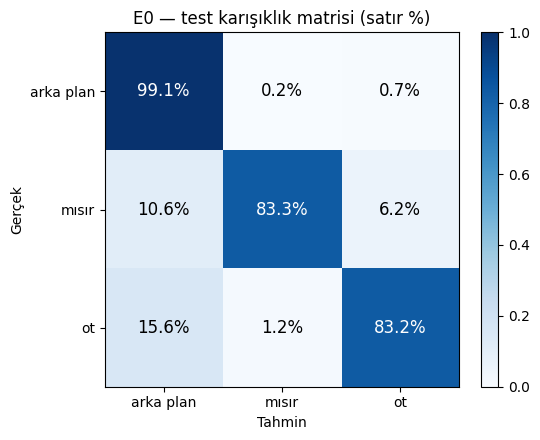

In [5]:
model = model_olustur(3, 3)
model.load_state_dict(torch.load(f'{CKPT_DIR}/E0_rgb_3s.pt'))

ds_te = OtDataset(splits['test'], 'rgb', 3)
cm_va, cm_va_t, _ = degerlendir(model, OtDataset(splits['val'], 'rgb', 3), 3)
cm_te, cm_te_t, _ = degerlendir(model, ds_te, 3)
mv, mt = metrikler(cm_va), metrikler(cm_te)

# Sınıf bazında val ve test
tablo = pd.DataFrame({'val IoU': mv['iou'], 'test IoU': mt['iou'],
                      'test precision': mt['precision'], 'test recall': mt['recall'], 'test F1': mt['f1']},
                     index=SIN3).mul(100).round(1)
print(tablo.to_string())

# Makale ile karşılaştırma (makale: DeepLabv3+, test seti, 3 sınıf, %)
print(f"\nmIoU  → bizim val {mv['miou'] * 100:.2f} | bizim TEST {mt['miou'] * 100:.2f} "
      f"| makale RGB 79.33 | makale MSI 82.90")
print(f"Saha  → test ot recall %{mt['ot_recall'] * 100:.1f} | test mısırın ot sanılma oranı %{mt['misir_fp'] * 100:.1f}")

# Tarih bazında test mIoU (+ her tarihte kaç görüntü olduğu)
n_tarih = pd.Series([a[:10] for a in splits['test']]).value_counts()
print('\nTarih başına TEST mIoU:', {d: f"{metrikler(c)['miou'] * 100:.1f} (n={n_tarih[d]})" for d, c in cm_te_t.items()})

# Test karışıklık matrisi (satır normalize: her gerçek sınıfın piksellerinin nereye gittiği)
cmn = cm_te.cpu().numpy().astype(float)
cmn = cmn / cmn.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f'{cmn[i, j] * 100:.1f}%', ha='center', va='center',
                color='white' if cmn[i, j] > 0.5 else 'black', fontsize=12)
ax.set_xticks(range(3), SIN3); ax.set_yticks(range(3), SIN3)
ax.set_xlabel('Tahmin'); ax.set_ylabel('Gerçek'); ax.set_title('E0 — test karışıklık matrisi (satır %)')
fig.colorbar(im, fraction=0.046)
plt.tight_layout(); plt.savefig(f'{RES_DIR}/E0_test_cm.png', dpi=150); plt.show()

# Kaydet (04_degerlendirme'de tüm deneylerle birlikte tabloya girecek)
with open(f'{RES_DIR}/E0_rgb_3s_test.json', 'w') as f:
    json.dump({'test_miou': mt['miou'], 'test_iou': mt['iou'].tolist(),
               'test_ot_recall': mt['ot_recall'], 'test_misir_fp': mt['misir_fp']}, f, indent=2)